# Thực nghiệm thử tham số 3 mô hình trên tập A
Thử thay đổi một siêu tham số ở mỗi mô hình Logistic Regression, Random Forest và XGBoost trên tập A (36 đặc trưng). Các mô hình được đánh giá bằng Stratified 5-fold CV và chỉ số Macro-F1. Kết quả được đối chiếu giữa cấu hình gốc và cấu hình thử trên cùng tập A; không sử dụng tập test.
## 1. Thiết lập tham số

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold

SEED = 42
N_FOLDS = 5
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "ML01_Student_Dropout"]
project_dir = next((p for p in candidates if
    (p / "feature_b" / "common.py").is_file()
    and (p / "data" / "processed" / "development.csv").is_file()), None)
if project_dir is None:
    raise FileNotFoundError("Hãy mở notebook trong repository có thư mục ML01_Student_Dropout.")
sys.path.insert(0, str(project_dir / "feature_b"))
from common import load_development, evaluate

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-17_ThuThamSo_3MoHinh_TapA_Triet"
print("Dự án:", project_dir)
print("Lưu kết quả:", output_dir)


Dự án: D:\sgu-MAYHOC\ML01_Student_Dropout
Lưu kết quả: D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-17_ThuThamSo_3MoHinh_TapA_Triet


In [2]:
# Cấu hình gốc lấy từ bảng thiết lập ban đầu; mỗi cấu hình thử chỉ đổi 1 tham số.
configs = {
    'Logistic Regression': {
        "class": LogisticRegression, "scale_numeric": True,
        "baseline": {'C': 0.1, 'solver': 'lbfgs', 'max_iter': 3000, 'class_weight': 'balanced'},
        "trial": {'C': 0.1, 'solver': 'lbfgs', 'max_iter': 2000, 'class_weight': 'balanced'},
        "changed_parameter": 'max_iter: 3000 -> 2000',
    },
    'Random Forest': {
        "class": RandomForestClassifier, "scale_numeric": False,
        "baseline": {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'class_weight': 'balanced', 'random_state': 42, 'n_jobs': 1},
        "trial": {'n_estimators': 200, 'max_depth': 15, 'min_samples_leaf': 1, 'class_weight': 'balanced', 'random_state': 42, 'n_jobs': 1},
        "changed_parameter": 'max_depth: None -> 15',
    },
    'XGBoost': {
        "class": XGBClassifier, "scale_numeric": False,
        "baseline": {'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.1, 'objective': 'multi:softprob', 'num_class': 3, 'eval_metric': 'mlogloss', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': 1},
        "trial": {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'objective': 'multi:softprob', 'num_class': 3, 'eval_metric': 'mlogloss', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': 1},
        "changed_parameter": 'n_estimators: 150 -> 200',
    },
}
config_rows = []
for model_name, item in configs.items():
    for variant in ("baseline", "trial"):
        config_rows.append({"Mô hình": model_name, "Cấu hình": "Gốc" if variant == "baseline" else "Thử",
                            "Tham số thay đổi": item["changed_parameter"],
                            "Cấu hình đầy đủ": repr(item[variant]),
                            "Chuẩn hóa số": item["scale_numeric"]})
config_table = pd.DataFrame(config_rows)
display(config_table)

,Mô hình,Cấu hình,Tham số thay đổi,Cấu hình đầy đủ,Chuẩn hóa số
0,Logistic Regression,Gốc,max_iter: 3000 -> 2000,"{'C': 0.1, 'solver': 'lbfgs', 'max_iter': 3000...",True
1,Logistic Regression,Thử,max_iter: 3000 -> 2000,"{'C': 0.1, 'solver': 'lbfgs', 'max_iter': 2000...",True
2,Random Forest,Gốc,max_depth: None -> 15,"{'n_estimators': 200, 'max_depth': None, 'min_...",False
3,Random Forest,Thử,max_depth: None -> 15,"{'n_estimators': 200, 'max_depth': 15, 'min_sa...",False
4,XGBoost,Gốc,n_estimators: 150 -> 200,"{'n_estimators': 150, 'max_depth': 6, 'learnin...",False
5,XGBoost,Thử,n_estimators: 150 -> 200,"{'n_estimators': 200, 'max_depth': 6, 'learnin...",False


## 2. Huấn luyện và đánh giá ba mô hình
Dùng cùng 5 fold phân tầng (seed 42) trên development.csv và chỉ sử dụng 36 đặc trưng thuộc tập A. Mỗi mô hình được đánh giá với cấu hình gốc và cấu hình thử, chỉ thay đổi một siêu tham số: fit_intercept (Logistic Regression), max_features (Random Forest) và subsample (XGBoost).

In [3]:
X_a, X_ab, y = load_development(data_path)
assert X_a.shape[1] == 36 and X_ab.shape[1] == 38
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
X = X_a
folds = list(cv.split(X, y))

summary_rows, fold_tables = [], []
for name, item in configs.items():
    for variant in ("baseline", "trial"):
        label = "Gốc" if variant == "baseline" else "Thử"
        print(f"Đang chạy: {name} - {label} (A)")
        model = item["class"](**item[variant])
        summary, fold_scores = evaluate(
            name, model, item["scale_numeric"], 'A', X, y, folds
        )
        summary.update({
            "configuration": label,
            "changed_parameter": item["changed_parameter"],
            "cv_macro_f1_std": fold_scores["macro_f1"].std(ddof=1),
        })
        fold_scores["configuration"] = label
        fold_scores["changed_parameter"] = item["changed_parameter"]
        summary_rows.append(summary)
        fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)
comparison = results.pivot(index="model", columns="configuration",
                           values="cv_macro_f1").reset_index()
comparison["Chênh lệch (Thử - Gốc)"] = comparison["Thử"] - comparison["Gốc"]
display(results.round(6))
display(comparison.round(6))


3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang chạy: Logistic Regression - Gốc (A)
Đang chạy: Logistic Regression - Thử (A)
Đang chạy: Random Forest - Gốc (A)
Đang chạy: Random Forest - Thử (A)
Đang chạy: XGBoost - Gốc (A)
Đang chạy: XGBoost - Thử (A)


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate,configuration,changed_parameter,cv_macro_f1_std
0,Logistic Regression,A,36,0.717353,0.733509,0.618898,0.823430,Gốc,max_iter: 3000 -> 2000,0.020339
1,Logistic Regression,A,36,0.717353,0.733509,0.618898,0.823430,Thử,max_iter: 3000 -> 2000,0.020339
2,Random Forest,A,36,0.676448,0.766051,0.288189,0.949066,Gốc,max_depth: None -> 15,0.023100
3,Random Forest,A,36,0.713776,0.751099,0.453543,0.907187,Thử,max_depth: None -> 15,0.022307
4,XGBoost,A,36,0.713649,0.760774,0.434646,0.916808,Gốc,n_estimators: 150 -> 200,0.018016
5,XGBoost,A,36,0.710709,0.763412,0.433071,0.910017,Thử,n_estimators: 150 -> 200,0.018364


configuration,model,Gốc,Thử,Chênh lệch (Thử - Gốc)
0,Logistic Regression,0.717353,0.717353,0.000000
1,Random Forest,0.676448,0.713776,0.037327
2,XGBoost,0.713649,0.710709,-0.002940


## 3. So sánh và lưu kết quả


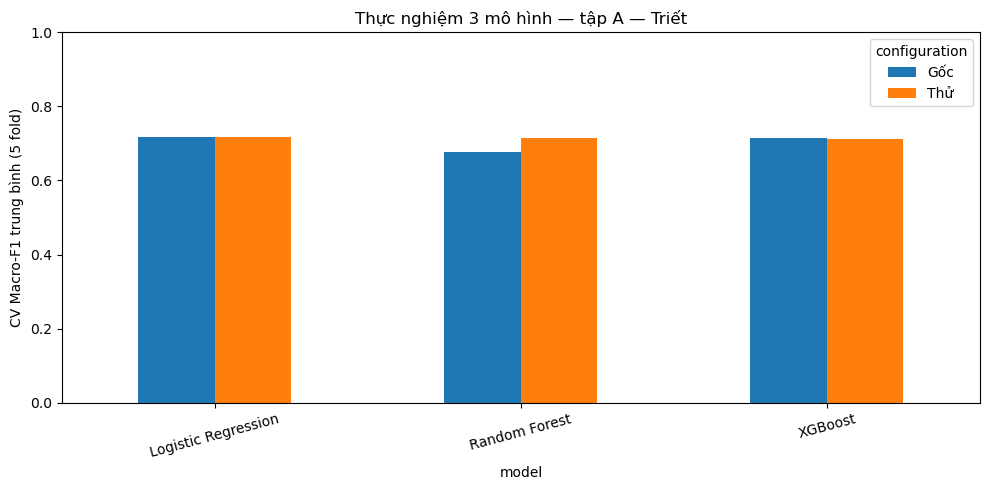

Đã lưu 5 file vào: D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-17_ThuThamSo_3MoHinh_TapA_Triet


In [4]:
# Chỉ ghi file khi toàn bộ 6 cấu hình đã đánh giá xong.
output_dir.mkdir(parents=True, exist_ok=True)
info = pd.DataFrame([{
    "Người thực hiện": "Trần Minh Triết",
    "Ngày": "17/11/2026",
    "Lần thực nghiệm": 'A - bộ tham số mới',
    "Dữ liệu": "data/processed/development.csv",
    "Tập đặc trưng": 'A',
    "Số mẫu": len(y),
    "Số đặc trưng": X.shape[1],
    "CV": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)",
    "Chỉ số chính": "CV Macro-F1",
    "sklearn": sklearn.__version__,
}])
with pd.ExcelWriter(output_dir / "ket_qua.xlsx", engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.to_excel(writer, sheet_name="So sanh goc va thu", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    info.to_excel(writer, sheet_name="Thong tin", index=False)
results.to_csv(output_dir / "ket_qua_tong_hop.csv", index=False, encoding="utf-8-sig")
fold_results.to_csv(output_dir / "diem_tung_fold.csv", index=False, encoding="utf-8-sig")
comparison.to_csv(output_dir / "so_sanh_goc_va_thu.csv", index=False, encoding="utf-8-sig")

ax = comparison.set_index("model")[["Gốc", "Thử"]].plot.bar(figsize=(10, 5))
ax.set_ylim(0, 1)
ax.set_ylabel("CV Macro-F1 trung bình (5 fold)")
ax.set_title("Thực nghiệm 3 mô hình — tập A — Triết")
ax.tick_params(axis="x", rotation=15)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(output_dir / "so_sanh_macro_f1.png", dpi=180)
plt.show()
plt.close(fig)
print("Đã lưu 5 file vào:", output_dir)


## 4. Nhận xét
**Nhận xét:** Sau khi thử tham số trên tập A, Random Forest cải thiện rõ nhất khi giảm max_depth từ None xuống 15, CV Macro-F1 tăng từ 0,676448 lên 0,713776 (+0,037327). Logistic Regression giữ nguyên kết quả 0,717353 khi giảm max_iter từ 3000 xuống 2000. Trong khi đó, XGBoost giảm nhẹ từ 0,713649 xuống 0,710709 khi tăng n_estimators từ 150 lên 200. Nhìn chung, việc giới hạn độ sâu cây giúp Random Forest cải thiện hiệu quả, còn tăng số cây của XGBoost chưa mang lại kết quả tốt hơn.